# MPV (Mapping Police Violence) Data Exploration and Cleaning

---
***MPV** is a public database, built mainly from news reports, of people killed by the police in the US.*

*Part of it is copied from two other databases:*
  - *`wapo_…` from the <span style="color:red">Washington Post</span>'s police shootings database <span style="color:red">used in the study</span>*
  - *`fe_id`  links to <span style="color:red">Fatal Encounters</span>*

The copy in this repo was exported by hand from MPV's Airtable share on 6 May 2026.
It has 15,711 deaths from 2013 to 2026 with 62 columns.

<hr style="border:none; border-top:0.5px solid #999">

This project uses 17 raw columns between 2015-2021, recoded in `data/1_data_notebooks/1_1_mpv/handmade/mpv_label_recodes.csv`.

Each column is explored, selected, recoded, and cleaned here, through code and handmade tables.

<hr style="border:none; border-top:0.5px solid #999">

The notebook is split into two blocks:

**Block 1: uses the whole MPV raw table**

- lists all columns and counts their labels
- the columns the study uses are hand-selected in `data/1_data_notebooks/1_1_mpv/handmade/mpv_select_col.csv`
- parses the dates
- deaths per year visual → <span style="color:yellow">temporal_coverage.png</span>
- recodes state names → two-letter codes
- checks (the decisions are recorded in `data/1_data_notebooks/1_1_mpv/handmade/mpv_duplicates.csv` and `data/1_data_notebooks/1_1_mpv/handmade/mpv_wrong_locations.csv`):
    - duplicates
    - deaths without coordinates
    - locations shared by different cities
    - locations outside their recorded state

**Block 2: uses only the study's columns** (except the missing-entries heat map, which reads every year)
- drops what the checks found
- checks the ages
- explores the labels of each study-relevant column
- missing entries visual → <span style="color:yellow">missing_by_year.png</span>
- cause of death separate recoding → one yes / no column per force (lethal, non-lethal), plus `less_lethal_also`
- <span style="color:red">**saves**</span> `data/1_data_notebooks/1_1_mpv/mpv.parquet` (+ `mpv.csv`): the clean death table

<hr style="border:none; border-top:0.5px solid #999">

**Design choice:** categories < 1% after recoding become **missing** (`mpv_label_recodes.csv`)

---


### Block 1

<div style="border:1px solid #999; background:#999; padding:8px">
</div>

### Imports and setup

---
- Applies the shared plot style
- Loads the project window from `shared/config.py`

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from shared.paths import MPV_RAW_DIR, MPV_HANDMADE_DIR, TIGER_RAW_DIR, MPV_DIR, OUTPUTS_DIR
from shared.io_utils import write_parquet
from shared.config import WINDOW_START, WINDOW_END
from shared.plotting import setup_plotting, save_fig, PALETTE

setup_plotting()

OUT_DIR = OUTPUTS_DIR / "1_1_mpv"

### Load the raw file

---

In [2]:
mpv = pd.read_csv(MPV_RAW_DIR / "mpv_data.csv")
print(f"MPV: {len(mpv):,} rows, {len(mpv.columns)} cols")

# counting how many different labels each column holds (empty cells are not a label)
labels_per_column = mpv.nunique().rename_axis("column").to_frame("labels")
print(labels_per_column.to_string())

MPV: 15,711 rows, 62 cols
                                   labels
column                                   
name                                15114
age                                    96
gender                                  6
race                                    7
victim_image                         9637
date                                 4627
street_address                      15355
city                                 4494
state                                  51
zip                                  7883
county                               1327
agency_responsible                   4541
ori                                  4996
cause_of_death                        171
circumstances                       15624
disposition_official                  955
officer_charged                       276
news_urls                           15605
signs_of_mental_illness                 4
allegedly_armed                         4
wapo_armed                            262
wapo_thr

<div style="border:1px solid #999; padding:8px">
The columns to be used for the study are hand-selected and saved in <code>data/1_data_notebooks/1_1_mpv/handmade/mpv_select_col.csv</code>.
</div>

### Parse the dates

---
MPV stores dates as text, so they are turned into real dates.

In [3]:
# an unreadable one becomes `NaT` instead of crashing
mpv["_date"] = pd.to_datetime(mpv["date"], errors="coerce")

n_failed = mpv["_date"].isna().sum()
print(f"Unparseable dates: {n_failed:,} ({n_failed / len(mpv):.1%})")

in_window = mpv[mpv["_date"].between(WINDOW_START, WINDOW_END)]

Unparseable dates: 0 (0.0%)


### Deaths per year → <span style="color:yellow">temporal_coverage.png</span>

---
2026 runs only to the export (6 May 2026), so its low count is not a drop.

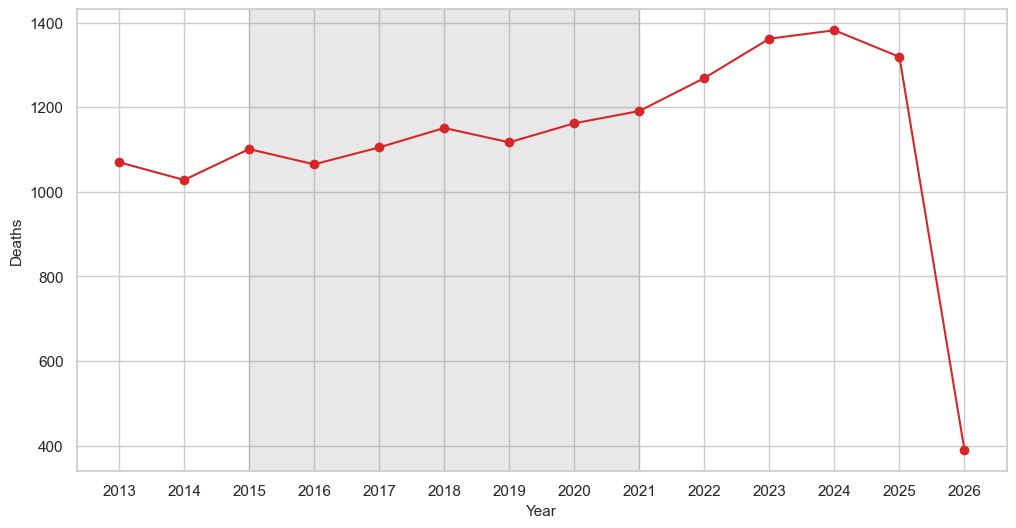

In [4]:
yearly = mpv["_date"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(yearly.index, yearly, marker="o", color=PALETTE[1])

ax.axvspan(WINDOW_START.year, WINDOW_END.year, alpha=0.18, color="gray")

# every year labeled; else matplotlib would skip some
ax.set(xticks=yearly.index, xlabel="Year", ylabel="Deaths")
save_fig(fig, "temporal_coverage", OUT_DIR)

### State names recoding

---
The Census files name each state by its two-letter code, so MPV's full names are recoded to match.

In [5]:
print(f"Distinct state names: {in_window['state'].nunique()}")

# each state's full name and two-letter code: "California" -> "CA"
us_states = gpd.read_file(TIGER_RAW_DIR / "states_2020.gpkg")
STATE_CODES: dict[str, str] = dict(zip(us_states["NAME"], us_states["STUSPS"]))

in_window["state"] = in_window["state"].map(STATE_CODES)

Distinct state names: 51


### Checks

---

#### Check 1. Duplicates

<hr style="border:none; border-top:0.5px solid #999">

Checking for duplicates: **names**, **dates** and **city**.
- multiple crash victims are separate deaths: kept
- Ray Wyatt (`5875`, `5876`) is one man recorded twice: `5876` is dropped at the start of block 2

In [6]:
key = ["name", "date", "city"]

# `keep=False`: mark every row of such a group, not only the repeats
is_repeated = in_window.duplicated(key, keep=False)
duplicate = in_window[is_repeated]

# the group's news links once each: the headline gives how many died
for (name, date, city), group in duplicate.groupby(key):
    print(f"\n{name}, {date}, {city}")
    for _, row in group.iterrows():
        print(f"  {row['mpv_id']}: {row['gender']}, age {row['age']}, {row['cause_of_death']}")
    for link in group["news_urls"].str.split().explode().drop_duplicates():
        print(f"  {link}")


Name Withheld, 11/29/2018, Boulevard
  6444: Male, age nan, Vehicle
  6441: Female, age nan, Vehicle
  6442: Male, age nan, Vehicle
  https://www.usnews.com/news/best-states/california/articles/2018-11-30/3-dead-8-injured-after-fleeing-truck-rollover-in-california
  https://www.usatoday.com/story/news/nation/2018/11/29/border-patrol-chase-3-die-after-pickup-crashes-near-san-diego/2159071002/

Name Withheld, 4/6/2019, Santa Teresa
  6837: Unknown, age nan, Vehicle
  6838: Unknown, age nan, Vehicle
  https://www.elpasotimes.com/story/news/immigration/2019/04/07/border-patrol-chase-ends-crash-2-migrants-killed-new-mexico/3394408002/
  https://www.elpasotimes.com/story/news/crime/2019/07/09/el-paso-driver-robert-acevedo-pleads-guilty-deadly-migrant-crash-border-patrol-chase-new-mexico/1687717001/
  https://kfoxtv.com/news/local/two-dead-9-apprehended-in-smuggling-incident-in-southwest-new-mexico

Ray Wyatt, 5/21/2018, Joshua Tree
  5876: Male, age 58.0, Gunshot
  5875: Male, age 58.0, Gun

<div style="border:1px solid #999; padding:8px">
Decisions are saved in <code>data/1_data_notebooks/1_1_mpv/handmade/mpv_duplicates.csv</code>.
</div>

#### Check 2. Missing coordinates

<hr style="border:none; border-top:0.5px solid #999">

- 1 death has none (mpv_id 17017, Oklahoma City), so it cannot be placed on the map
- it is dropped at the start of block 2

In [7]:
lat, lon = in_window["latitude"], in_window["longitude"]

no_xy = in_window[lat.isna()]
print(f"Without coordinates: {len(no_xy)}")
print(no_xy[["mpv_id", "city", "state"]].to_string(index=False))

Without coordinates: 1
 mpv_id           city state
  17017 Oklahoma City     OK


#### Check 3. Shared locations

<hr style="border:none; border-top:0.5px solid #999">

- 2 are correct (1 the same intersection under two cities, 1 one place named two ways) and kept
- 5 are wrong highway locations; 2 deaths on 2 of them lie in their own state, so Check 4 can't find them

In [8]:
SHOW = ["mpv_id", "city", "state", "street_address"]

city = in_window["city"].str.strip().str.lower()

by_location = city.groupby([lat, lon])

cities_at_location = by_location.transform("nunique")

shared = in_window[cities_at_location > 1]
n_shared_locations = len(shared.drop_duplicates(["latitude", "longitude"]))
print(f"Locations shared by different cities: {n_shared_locations}  |  deaths on them: {len(shared)}")

shared_sorted = shared.sort_values(["latitude", "longitude"])
print(shared_sorted[SHOW + ["latitude", "longitude"]].to_string(index=False, max_colwidth=40))

Locations shared by different cities: 7  |  deaths on them: 16
 mpv_id        city state                       street_address  latitude   longitude
   5340      Mobile    AL      I-10 and Dauphin Island Parkway 30.527993  -99.852776
   4713 Robertsdale    AL                                 I-10 30.527993  -99.852776
   2386    Glendale    AZ North 67th Ave. and West Peoria Ave. 33.581756 -112.202758
   2362      Peoria    AZ               67th Avenue and Peoria 33.581756 -112.202758
   6088      Luxora    AR                                 I-55 36.128721  -89.754549
   4940   St. Louis    MO                       I-55 and I-270 36.128721  -89.754549
   6968  Vero Beach    FL                 I-95 Mile Marker 152 36.877995  -77.403736
   5864    Richmond    VA         I-95 and Chamberlayne Avenue 36.877995  -77.403736
   9719    Sandston    VA                       I-64 and I-295 38.155794  -83.612394
   8972       Ridge    VA            I-64 near mile marker 173 38.155794  -83.612394
  

#### Check 4. Location outside the recorded state

<hr style="border:none; border-top:0.5px solid #999">

The state outlines come from the Census Bureau's 2020 cartographic boundary file (`data/0_raw/1_2_tiger/states_2020.gpkg`).

- 22 deaths lie in another state than recorded: 21 have a wrong location (mostly highway addresses)
- 1 sits on the state line (Fulton, Kentucky, East Stateline Drive) and is kept

In [9]:
state_shapes = us_states[["STUSPS", "geometry"]]

# MPV gives plain latitude and longitude with no coordinate system
# so they are read in the state file's NAD83, close enough to GPS to need no conversion
located = in_window[lat.notna()]
lonlat = gpd.points_from_xy(located["longitude"], located["latitude"])
deaths_gdf = gpd.GeoDataFrame(located, geometry=lonlat, crs=state_shapes.crs)

# `how="left"` keeps a death that falls in no state: its missing `STUSPS` never equals the recorded state, so it lands in `wrong`
placed = deaths_gdf.sjoin(state_shapes, how="left")

wrong = placed[placed["STUSPS"] != placed["state"]]
print(f"In another state than recorded: {len(wrong)}")

wrong_sorted = wrong.sort_values("STUSPS")
print(wrong_sorted[SHOW + ["STUSPS"]].to_string(index=False, max_colwidth=40))

In another state than recorded: 22
 mpv_id        city state                   street_address STUSPS
   7915      Turner    OR              I-5 Mile marker 248     CA
   7200 Martinsburg    MO                 US-54 and Hwy BB     KS
   6982     Winston    MO                    I-35, Exit 64     KS
   9719    Sandston    VA                   I-64 and I-295     KY
   8972       Ridge    VA        I-64 near mile marker 173     KY
   7248        Dale    IN                             I-64     KY
   4702    Brighton    MI           Spencer Road and US-23     KY
   4326     English    IN                             I-64     KY
   8926      Mobile    AL                   US-90 and I-10     LA
   9567   New Salem    ND                             I-94     MN
   6595  White Lake    SD                             I-90     MN
   6425     Detroit    MI                    I-94 and I-75     MN
   9360      Quimby    LA US-65 and Ashley Plantation Road     MO
   6088      Luxora    AR                

<div style="border:1px solid #999; padding:8px">
Decisions are saved in <code>data/1_data_notebooks/1_1_mpv/handmade/mpv_wrong_locations.csv</code>.
</div>

### Block 2

<div style="border:1px solid #999; background:#999; padding:8px">
</div>

### Selected columns

---
From here on only the 17 columns over the 2015-2021 window with parsed dates.

In [10]:
SELECTED_COLUMNS = pd.read_csv(MPV_HANDMADE_DIR / "mpv_select_col.csv")["column"]

study_deaths_preclean = in_window[[*SELECTED_COLUMNS, "_date"]]
print(f"{len(study_deaths_preclean):,} deaths × {len(SELECTED_COLUMNS)} selected columns")

7,892 deaths × 17 selected columns


### Drop the inconsistencies

---
- 1 duplicate (Check 1)
- 1 death without coordinates (Check 2)
- 23 wrong locations (Checks 3 and 4)

In [11]:
duplicates = pd.read_csv(MPV_HANDMADE_DIR / "mpv_duplicates.csv")
wrong_locations = pd.read_csv(MPV_HANDMADE_DIR / "mpv_wrong_locations.csv")
duplicate_ids = duplicates.loc[duplicates["decision"] == "drop", "mpv_id"]
wrong_location_ids = wrong_locations.loc[wrong_locations["decision"] == "drop", "mpv_id"]

study_deaths = study_deaths_preclean[~study_deaths_preclean["mpv_id"].isin(duplicate_ids)]  # `~` = not
study_deaths = study_deaths[~study_deaths["mpv_id"].isin(wrong_location_ids)]
study_deaths = study_deaths.dropna(subset=["latitude", "longitude"])
print(f"{len(study_deaths):,} deaths left after cleaning")

7,867 deaths left after cleaning


### Ages

---

In [12]:
age = study_deaths["age"]
print(age.describe().drop(["count", "std"]).round(1).to_string())

print(f"Blank entries: {age.isna().sum()}")

# a typo like 3.5 or 350 would show here or in the range above
whole = (age.dropna() % 1 == 0).all()
print(f"All whole numbers: {whole}")

mean    37.0
min      1.0
25%     27.0
50%     35.0
75%     45.0
max     92.0
Blank entries: 264
All whole numbers: True


### Label exploration

---
Counting each column's labels, descending; an empty cell is not a label

In [13]:
labels_per_column = study_deaths[SELECTED_COLUMNS].nunique().sort_values(ascending=False)
print(labels_per_column.rename_axis("column").to_frame("labels").to_string())

                         labels
column                         
mpv_id                     7867
latitude                   7768
longitude                  7767
date                       2414
officer_charged             142
wapo_armed                  128
cause_of_death              109
age                          86
state                        51
encounter_type                8
race                          7
wapo_flee                     7
gender                        6
wapo_threat_level             6
signs_of_mental_illness       4
allegedly_armed               4
call_for_service              3


### Study-relevant labels

---
Explored in two sections:

1. **Under 10 labels, every label with its count:** `race`, `gender`, `allegedly_armed`, `signs_of_mental_illness`, `encounter_type`, `call_for_service`, `wapo_threat_level`, `wapo_flee`
2. **Over 10 labels, only the 15 most common:** `wapo_armed`, `cause_of_death`, `officer_charged`

In [14]:
for col in ["race", "gender", "allegedly_armed", "signs_of_mental_illness", "encounter_type",
            "call_for_service", "wapo_threat_level", "wapo_flee"]:
    print(f"\n--- {col} ---")
    print(study_deaths[col].value_counts(dropna=False).to_string())


--- race ---
race
White                                   3672
Black                                   2030
Hispanic                                1462
Unknown race                             387
American Indian and Alaska Native        138
Asian                                    126
Native Hawaiian and Pacific Islander      52

--- gender ---
gender
Male                  7445
Female                 406
Transgender Female       6
Unknown                  5
Transgender Male         4
Non-Binary               1

--- allegedly_armed ---
allegedly_armed
Allegedly Armed                       5608
Unarmed/Did Not Have Actual Weapon    1181
Unclear                                585
Vehicle                                492
NaN                                      1

--- signs_of_mental_illness ---
signs_of_mental_illness
No                     5028
Yes                    1673
Unknown                 766
Drug or Alcohol Use     344
NaN                      56

--- encounter_type ---
enco

In [15]:
for col in ["wapo_armed", "cause_of_death", "officer_charged"]:
    print(f"\n--- {col} ---")
    print(study_deaths[col].value_counts(dropna=False).head(15).to_string())


--- wapo_armed ---
wapo_armed
Gun               4062
Knife             1050
No Object          671
Vehicle            491
Undetermined       393
NaN                338
Toy Weapon         234
Unknown Weapon      76
Machete             58
Taser               36
Sword               34
Ax                  21
Screwdriver         19
Baseball Bat        19
Hammer              18

--- cause_of_death ---
cause_of_death
Gunshot                                     7036
Gunshot,Taser                                300
Vehicle                                      127
Taser                                        117
Physical Restraint                            48
Taser,Physical Restraint                      45
Gunshot,Other                                 16
Taser,Physical Restraint,prone restraint      14
Beaten                                        13
Other                                          8
Taser,Physical Restraint,Other                 7
Gunshot,Bean bag                              

<div style="border:1px solid #999; padding:8px">
What each label becomes is decided by hand and recorded, with its reason, in <code>data/1_data_notebooks/1_1_mpv/handmade/mpv_label_recodes.csv</code>.
</div>

### Missing entries → <span style="color:yellow">missing_by_year.png</span>

---
The columns with 100+ missing entries, as a share of each year's deaths:
- weapon goes missing far more often in 2022-24

In [16]:
UNKNOWN_LABELS = {
    "unknown", "unknown race", "unclear", "unavailable", "undetermined",
}

def is_missing(values: pd.Series) -> pd.Series:
    """True for an empty cell or a 'we-don't-know' label."""
    return values.isna() | values.astype(str).str.strip().str.lower().isin(UNKNOWN_LABELS)


# `kind="stable"`: ties keep the column order
miss_counts = study_deaths[SELECTED_COLUMNS].apply(is_missing).sum().sort_values(ascending=False, kind="stable")

missing_pct = (miss_counts / len(study_deaths) * 100).round(1)
print(pd.DataFrame({"missing_n": miss_counts, "missing_pct": missing_pct}).to_string())

                         missing_n  missing_pct
wapo_flee                     1011         12.9
signs_of_mental_illness        822         10.4
wapo_threat_level              807         10.3
wapo_armed                     731          9.3
allegedly_armed                586          7.4
race                           387          4.9
call_for_service               387          4.9
age                            264          3.4
officer_charged                 15          0.2
gender                           5          0.1
cause_of_death                   1          0.0
mpv_id                           0          0.0
date                             0          0.0
latitude                         0          0.0
longitude                        0          0.0
state                            0          0.0
encounter_type                   0          0.0


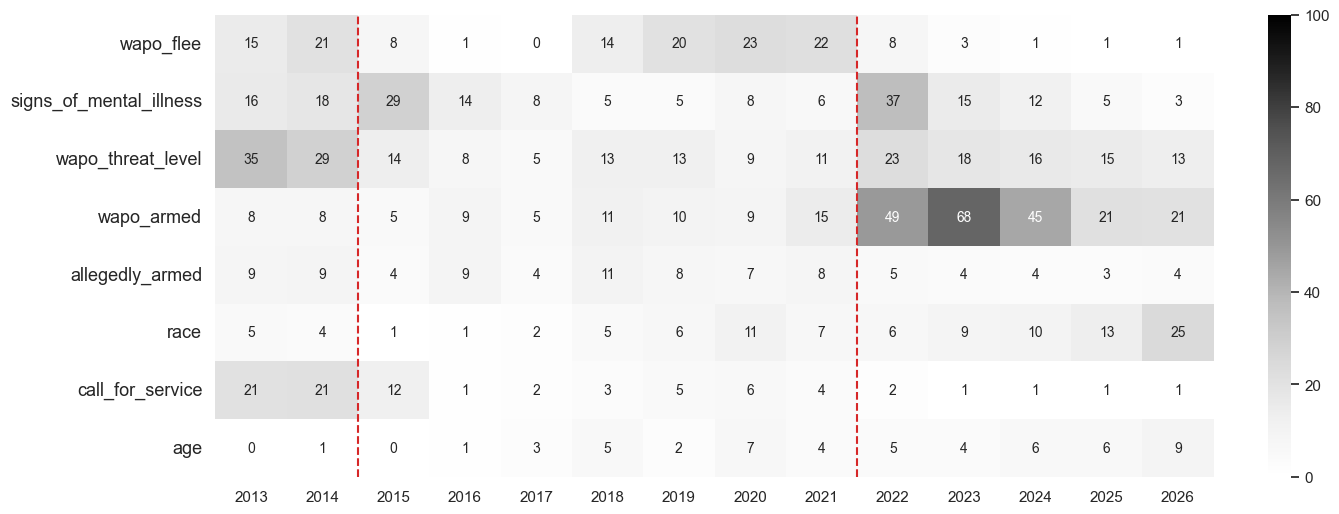

In [17]:
missing_cols = miss_counts[miss_counts >= 100].index

# every year in the file, not only the project window
year = mpv["_date"].dt.year
cell_missing = mpv[missing_cols].apply(is_missing)
# the mean of True / False = the share of True; `.T`: the columns become the rows
missing_by_year = cell_missing.groupby(year).mean().T * 100

fig, ax = plt.subplots(figsize=(14, 6))
# gray cells from 0 (white) to 100 (black), the % written in each cell
sns.heatmap(
    missing_by_year,
    cmap="Greys", vmin=0, vmax=100, annot=True,
    fmt=".0f", annot_kws={"fontsize": 10},
    cbar_kws={"fraction": 0.03}
)

# dashed lines around the project window; each year is one cell wide
years = list(missing_by_year.columns)
window_left = years.index(WINDOW_START.year)
window_right = years.index(WINDOW_END.year) + 1
ax.axvline(window_left, color=PALETTE[1], linestyle="--")
ax.axvline(window_right, color=PALETTE[1], linestyle="--")
ax.set(xlabel="")
ax.tick_params(axis="y", labelsize=13)
save_fig(fig, "missing_by_year", OUT_DIR)

### Label recoding

---
The labels are recoded to the study's categories as read from the handmade CSV.

`cause_of_death` is recoded in its own cell below.

In [18]:
recodes_all = pd.read_csv(MPV_HANDMADE_DIR / "mpv_label_recodes.csv", dtype=str, keep_default_na=False)
recodes = recodes_all[recodes_all["column"] != "(every column)"]  # an empty cell is missing already
recodes = recodes[recodes["column"] != "cause_of_death"]  # recoded in its own cell below

for col, rows in recodes.groupby("column"):
    to_label = dict(zip(rows["label"], rows["becomes"]))
    every_other = to_label.pop("(every other label)", None)  # the catch-all, where the column has one
    labels = study_deaths[col]
    has_row = labels.isin(to_label)

    # every label needs a row of its own, or the catch-all
    no_row = labels[labels.notna() & ~has_row].unique()
    assert every_other is not None or len(no_row) == 0, f"{col}: no row for {list(no_row)}"

    recoded = labels.map(to_label)
    if every_other is not None:
        recoded = recoded.mask(labels.notna() & ~has_row, every_other)
    study_deaths[col] = recoded.mask(recoded == "missing")  # "missing" -> an empty cell

for col in recodes["column"].unique():
    print(f"\n--- {col} ---")
    print(study_deaths[col].value_counts(dropna=False).to_string())


--- race ---
race
white       3672
black       2030
hispanic    1462
NaN          439
AIAN         138
asian        126

--- gender ---
gender
M      7445
F       406
NaN      16

--- allegedly_armed ---
allegedly_armed
armed      6100
unarmed    1181
NaN         586

--- signs_of_mental_illness ---
signs_of_mental_illness
neither             5028
mental illness      1673
NaN                  822
drugs or alcohol     344

--- encounter_type ---
encounter_type
violent crime                    2217
non-violent offense              1387
person with a weapon             1056
traffic stop                      792
domestic disturbance              736
mental health check               707
none or generalized suspicion     620
other crime against people        352

--- call_for_service ---
call_for_service
yes    4970
no     2510
NaN     387

--- wapo_threat_level ---
wapo_threat_level
attack    4949
other     2111
NaN        807

--- wapo_flee ---
wapo_flee
not fleeing    4523
car          

### Cause of death recoding

---
The study separates two types of force:
- **Lethal**: gunshot only
- **Less-lethal**: `taser`, `vehicle`, `restraint`
- *`other` is cut: under 1% of the deaths*

Recoded, some entries contain duplicates, for example:
`Taser,Physical Restraint,prone restraint` becomes `taser, restraint, restraint`

To count only once per force, they are turned into yes/no columns.

A new `less_lethal_also` column counts as yes **when a lethal force is used together with a less-lethal force**. This design decision intends to show that in these situations, less-lethal means were also tried. It is left empty for every death not shot, so its share reads among the shot deaths.

In [19]:
cause_recodes = recodes_all[recodes_all["column"] == "cause_of_death"]
to_force = dict(zip(cause_recodes["label"], cause_recodes["becomes"]))
forces = [f for f in cause_recodes["becomes"].unique() if f != "missing"]  # gunshot, taser, vehicle, restraint

labels = study_deaths["cause_of_death"].str.split(",")
no_row = set(labels.explode()) - set(to_force)
assert not no_row, f"cause_of_death: no row for {sorted(no_row)}"

# recoded, a set keeps each force once per death; a cut label marks none
death_forces = labels.map(lambda row: {to_force[label] for label in row})
for force in forces:
    study_deaths[force] = death_forces.map(lambda found: force in found)

# a gunshot listed together with a less-lethal force; empty for every death not shot, so its share reads among the shot deaths
study_deaths["less_lethal_also"] = study_deaths[["taser", "vehicle", "restraint"]].any(axis=1).astype("boolean").where(study_deaths["gunshot"])
study_deaths = study_deaths.drop(columns="cause_of_death")

### Save the clean table

---

In [20]:
clean = study_deaths.drop(columns="date").rename(columns={"_date": "date"})

out_path = MPV_DIR / "mpv.parquet"
write_parquet(clean, out_path)
print(f"Saved: 1_1_mpv/mpv.parquet + mpv.csv ({len(clean):,} deaths × {clean.shape[1]} cols)")

Saved: 1_1_mpv/mpv.parquet + mpv.csv (7,867 deaths × 21 cols)
